# Temporal Image Change Detection Using Computer Vision
### Mini Project | Python, OpenCV, NumPy and SSIM

**Objective:** Compare two images of the same scene captured at different times, identify changed regions, visualize the result, and estimate the percentage of pixels marked as changed.

This notebook includes a self-contained synthetic example so it runs without downloading a dataset. For a research submission, also test on real, correctly aligned image pairs and document the image source. The synthetic results demonstrate the pipeline; they are not evidence of real-world accuracy.

**Pipeline:** image input → preprocessing → pixel differencing → thresholding → morphological cleanup → visualization → evaluation.

In [6]:
## 1. Dependencies

In [7]:
# If needed:
# %pip install opencv-python numpy matplotlib scikit-image pandas

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
try:
    from skimage.metrics import structural_similarity
    SKIMAGE_AVAILABLE = True
except ImportError:
    SKIMAGE_AVAILABLE = False
    print("scikit-image not found; optional SSIM section will be skipped.")

plt.rcParams["figure.figsize"] = (12, 5)


OpenCV: 5.0.0
NumPy: 2.5.3


## 2. Input images or create a demo pair

To use your own images, enter their paths below. They should show the same location and be geometrically aligned. If paths are left empty, a reproducible synthetic example is generated.

Using synthetic demonstration images.


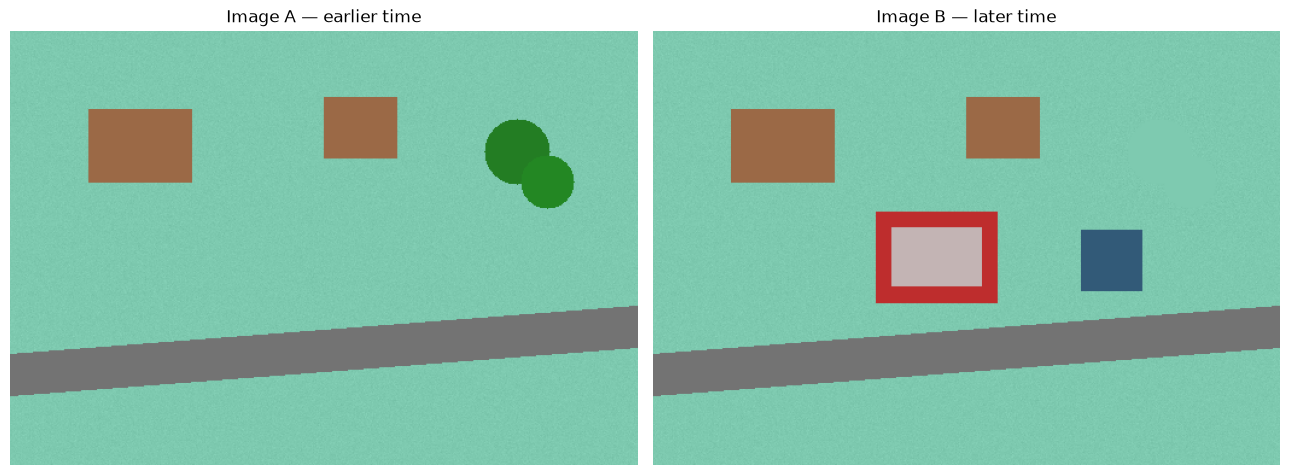

In [8]:
IMAGE_A_PATH = ""  # e.g. "data/before.png"
IMAGE_B_PATH = ""  # e.g. "data/after.png"

def make_demo_pair(height=360, width=520, seed=7):
    rng = np.random.default_rng(seed)
    base = np.zeros((height, width, 3), dtype=np.uint8)
    base[:] = (176, 202, 126)  # BGR background
    noise = rng.normal(0, 3, (height, width, 1))
    base = np.clip(base.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    cv2.line(base, (0, 285), (width, 245), (115, 115, 115), 34)
    cv2.rectangle(base, (65, 65), (150, 125), (70, 105, 155), -1)
    cv2.rectangle(base, (260, 55), (320, 105), (70, 105, 155), -1)
    cv2.circle(base, (420, 100), 27, (35, 125, 35), -1)
    cv2.circle(base, (445, 125), 22, (35, 135, 35), -1)
    after = base.copy()
    # Simulated new buildings and vegetation removal
    cv2.rectangle(after, (185, 150), (285, 225), (45, 45, 190), -1)
    cv2.rectangle(after, (198, 163), (272, 211), (180, 180, 195), -1)
    cv2.rectangle(after, (355, 165), (405, 215), (120, 90, 50), -1)
    cv2.circle(after, (420, 100), 27, (176, 202, 126), -1)
    cv2.circle(after, (445, 125), 22, (176, 202, 126), -1)
    gt = np.zeros((height, width), dtype=np.uint8)
    cv2.rectangle(gt, (185, 150), (285, 225), 255, -1)
    cv2.rectangle(gt, (355, 165), (405, 215), 255, -1)
    cv2.circle(gt, (420, 100), 27, 255, -1)
    cv2.circle(gt, (445, 125), 22, 255, -1)
    return base, after, gt

if IMAGE_A_PATH and IMAGE_B_PATH:
    image_a = cv2.imread(IMAGE_A_PATH)
    image_b = cv2.imread(IMAGE_B_PATH)
    if image_a is None or image_b is None:
        raise FileNotFoundError("Could not read an image. Verify both paths.")
    image_b = cv2.resize(image_b, (image_a.shape[1], image_a.shape[0]))
    ground_truth = None
    print("Loaded user-supplied images. Ensure they are aligned.")
else:
    image_a, image_b, ground_truth = make_demo_pair()
    print("Using synthetic demonstration images.")

def bgr_to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(bgr_to_rgb(image_a)); ax[0].set_title("Image A — earlier time"); ax[0].axis("off")
ax[1].imshow(bgr_to_rgb(image_b)); ax[1].set_title("Image B — later time"); ax[1].axis("off")
plt.tight_layout(); plt.show()


## 3. Method A — absolute pixel difference

For each pixel, compute the absolute grayscale intensity difference. Thresholding converts the difference image into a binary mask. Morphological opening and closing reduce isolated noise and fill small gaps.

**Limitation:** illumination, shadows, seasonal changes, sensor noise, or camera movement can produce false detections. Real imagery may require image registration and radiometric normalization.

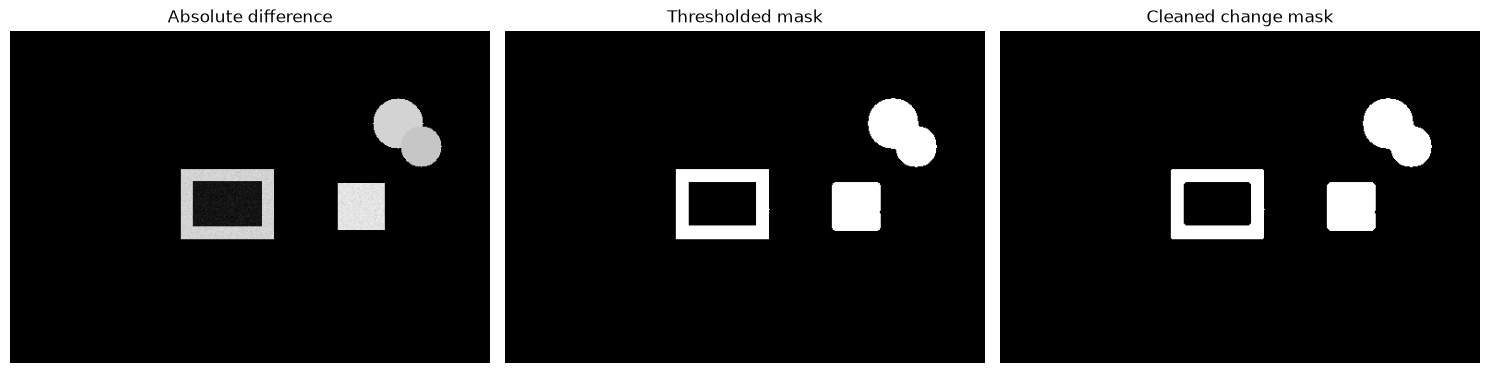

In [9]:
def pixel_difference(img_a, img_b, threshold=28, blur_kernel=5, min_area=80):
    gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
    gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)
    diff = cv2.absdiff(gray_a, gray_b)
    if blur_kernel and blur_kernel > 1:
        k = blur_kernel if blur_kernel % 2 else blur_kernel + 1
        diff_for_threshold = cv2.GaussianBlur(diff, (k, k), 0)
    else:
        diff_for_threshold = diff
    _, binary = cv2.threshold(diff_for_threshold, threshold, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel, iterations=2)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(cleaned, connectivity=8)
    filtered = np.zeros_like(cleaned)
    for label in range(1, count):
        if stats[label, cv2.CC_STAT_AREA] >= min_area:
            filtered[labels == label] = 255
    return diff, binary, filtered

difference, raw_mask, change_mask = pixel_difference(image_a, image_b)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(difference, cmap="gray"); ax[0].set_title("Absolute difference"); ax[0].axis("off")
ax[1].imshow(raw_mask, cmap="gray"); ax[1].set_title("Thresholded mask"); ax[1].axis("off")
ax[2].imshow(change_mask, cmap="gray"); ax[2].set_title("Cleaned change mask"); ax[2].axis("off")
plt.tight_layout(); plt.show()


## 4. Visualize and estimate changed pixel proportion

The overlay highlights detected pixels in red. The percentage is a proportion of image pixels, not a physical area measurement. A real-world area estimate requires georeferencing or known pixel resolution.

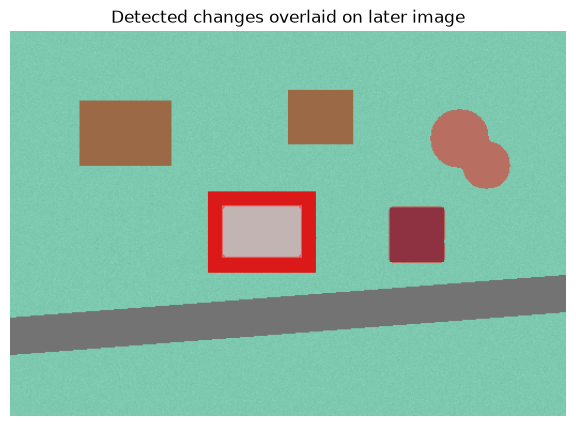

Detected pixels: 10,626 / 187,200
Estimated changed pixel proportion: 5.68%


In [10]:
def make_overlay(image, mask, alpha=0.45):
    overlay = image.copy()
    red = np.zeros_like(image)
    red[:] = (0, 0, 255)  # red in BGR
    selected = mask > 0
    overlay[selected] = cv2.addWeighted(image[selected], 1-alpha, red[selected], alpha, 0)
    return overlay

overlay = make_overlay(image_b, change_mask)
plt.figure(figsize=(12, 5))
plt.imshow(bgr_to_rgb(overlay)); plt.title("Detected changes overlaid on later image")
plt.axis("off"); plt.show()
changed_pixels = int(np.count_nonzero(change_mask))
total_pixels = int(change_mask.size)
print(f"Detected pixels: {changed_pixels:,} / {total_pixels:,}")
print(f"Estimated changed pixel proportion: {100*changed_pixels/total_pixels:.2f}%")


In [ ]:
## 5. Method B — SSIM-based structural difference 

The Structural Similarity Index (SSIM) compares local image structure. The local similarity map can be converted into a structural difference map and thresholded. SSIM is a comparison baseline, not a guarantee of better results; its threshold must be validated for the target data.

Whole-image SSIM similarity: 0.9530


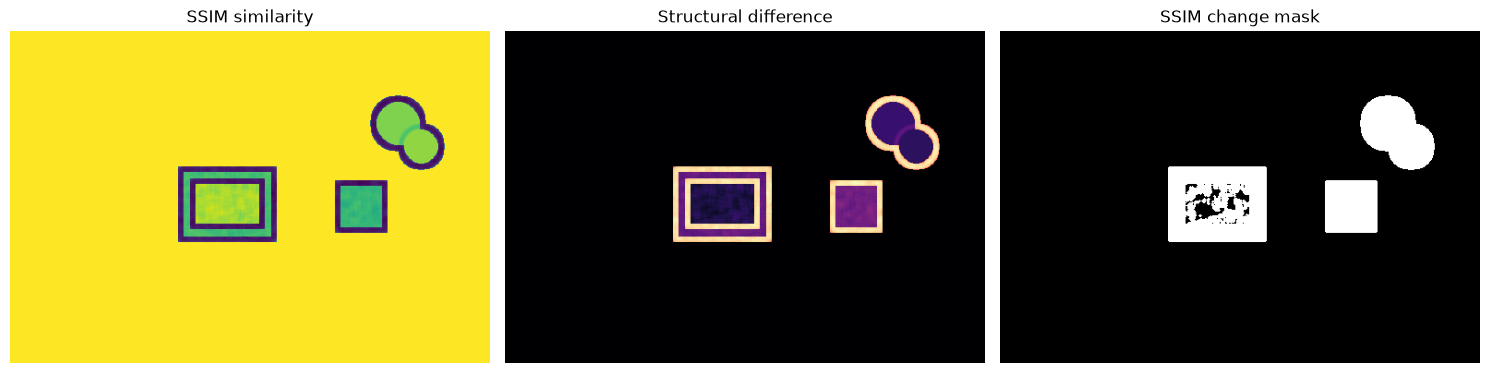

In [11]:
if SKIMAGE_AVAILABLE:
    gray_a = cv2.cvtColor(image_a, cv2.COLOR_BGR2GRAY)
    gray_b = cv2.cvtColor(image_b, cv2.COLOR_BGR2GRAY)
    score, similarity_map = structural_similarity(gray_a, gray_b, full=True, data_range=255)
    ssim_difference = 1.0 - similarity_map
    ssim_mask = (ssim_difference > 0.12).astype(np.uint8) * 255
    ssim_mask = cv2.morphologyEx(
        ssim_mask, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    )
    print(f"Whole-image SSIM similarity: {score:.4f}")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(similarity_map, cmap="viridis"); ax[0].set_title("SSIM similarity"); ax[0].axis("off")
    ax[1].imshow(ssim_difference, cmap="magma"); ax[1].set_title("Structural difference"); ax[1].axis("off")
    ax[2].imshow(ssim_mask, cmap="gray"); ax[2].set_title("SSIM change mask"); ax[2].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Install scikit-image to run SSIM: %pip install scikit-image")


## 6. Evaluation using the synthetic ground-truth mask

Precision, recall, F1 and intersection over union (IoU) can be calculated because the generated example has a known reference mask. These metrics apply only to this synthetic example. For real data, a manually labelled or dataset-provided reference mask is required.

In [12]:
def binary_metrics(predicted_mask, reference_mask):
    pred, ref = predicted_mask > 0, reference_mask > 0
    tp = int(np.logical_and(pred, ref).sum())
    fp = int(np.logical_and(pred, ~ref).sum())
    fn = int(np.logical_and(~pred, ref).sum())
    tn = int(np.logical_and(~pred, ~ref).sum())
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    iou = tp/(tp+fp+fn) if tp+fp+fn else 0.0
    accuracy = (tp+tn)/(tp+tn+fp+fn) if tp+tn+fp+fn else 0.0
    return {"TP":tp, "FP":fp, "FN":fn, "TN":tn, "Precision":precision,
            "Recall":recall, "F1":f1, "IoU":iou, "Accuracy":accuracy}

if ground_truth is not None:
    metrics = binary_metrics(change_mask, ground_truth)
    for name, value in metrics.items():
        print(f"{name:>10}: {value:.4f}" if isinstance(value, float) else f"{name:>10}: {value:,}")
else:
    print("No reference mask supplied; quantitative evaluation is unavailable.")


        TP: 10,340
        FP: 286
        FN: 3,427
        TN: 173,147
 Precision: 0.9731
    Recall: 0.7511
        F1: 0.8478
       IoU: 0.7358
  Accuracy: 0.9802


## 7. Threshold sensitivity experiment

A low threshold may detect subtle changes but increase false positives; a high threshold can miss genuine changes. Compare several values, then select parameters using multiple representative image pairs rather than tuning to one example.

In [13]:
thresholds = [10, 20, 28, 40, 60]
rows = []
for t in thresholds:
    _, _, mask_t = pixel_difference(image_a, image_b, threshold=t)
    row = {"threshold": t, "changed_pixel_percent": 100*np.count_nonzero(mask_t)/mask_t.size}
    if ground_truth is not None:
        row.update({k:v for k,v in binary_metrics(mask_t, ground_truth).items()
                    if k in ("Precision", "Recall", "F1", "IoU")})
    rows.append(row)
try:
    import pandas as pd
    display(pd.DataFrame(rows).round(4))
except ImportError:
    print(rows)


,threshold,changed_pixel_percent,Precision,Recall,F1,IoU
0,10,6.1127,0.9250,0.7689,0.8397,0.7238
1,20,5.9268,0.9327,0.7517,0.8324,0.7130
2,28,5.6763,0.9731,0.7511,0.8478,0.7358
3,40,5.3932,0.9994,0.7329,0.8457,0.7326
4,60,5.1886,0.9998,0.7054,0.8272,0.7053


## 8. Save result images

The following cell saves the binary mask, overlay, and absolute difference image. Include the images produced by your own run in the research report.

In [14]:
OUTPUT_DIR = "change_detection_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
cv2.imwrite(os.path.join(OUTPUT_DIR, "change_mask.png"), change_mask)
cv2.imwrite(os.path.join(OUTPUT_DIR, "change_overlay.png"), overlay)
cv2.imwrite(os.path.join(OUTPUT_DIR, "absolute_difference.png"), difference)
print("Saved outputs in:", os.path.abspath(OUTPUT_DIR))


Saved outputs in: C:\Users\KIIT\Downloads\change_detection_outputs


## 9. Discussion and conclusion

**Strengths:** interpretable baseline; runs on CPU; no training data required; provides a visual mask and pixel proportion.

**Limitations:** images must be aligned; illumination, shadows, seasons, and camera differences can cause false positives; pixel changes do not identify semantic categories; the synthetic example is not a real-world benchmark.

**Future work:** (1) align images with feature matching such as ORB, (2) evaluate on a public dataset with reference masks, (3) compare classical methods with Siamese networks or ChangeFormer, (4) report precision, recall, F1 and IoU across many scenes, and (5) document image resolution, dates and preprocessing.

**Conclusion:** This notebook implements temporal change detection using pixel differencing and optional SSIM. Interpret output as candidate changed regions and validate on real data before making application claims.